# 2조 보고서 수치 검산 · metrics.json v1.2 (김동민)
조윤호 님 보고서 v0.2에 나온 수치를 원본에서 다시 계산해 대조하고 `metrics.json`에 추가합니다.

**사용법**
1. **모두 실행** (Colab: 런타임 → 모두 실행 / 로컬: Run All)
2. 입력은 자동으로 찾습니다: 프로젝트 폴더(`data/raw/`, Colab은 공유 폴더 바로가기) → 노트북 옆 `data_part*.zip`·CSV → (Colab) 업로드 창. 로컬 Jupyter에서도 그대로 실행됩니다. ZIP이 없으면 FRED 원본 CSV 두 개(SOFRINDEX, DEXKOUS)를 함께 선택해 올려도 됩니다.
3. FRED 다운로드 일자는 v1.1 ZIP에 저장된 값을 자동으로 이어받습니다.
4. 마지막 셀에서 `data_part_v1.2.zip`이 내려받아집니다.

각 비교 표 아래에 `→ 전부 OK` 또는 `→ CHK n개`가 출력됩니다.

| 블록 | 내용 |
|---|---|
| 0 | 파일 준비 · 월별 테이블 재계산 · 기존 metrics와 일치 확인 |
| ① | 2020~2022 / 2023~2025 기간별 상관 |
| ② | 연준 정책 4구간별 금리·환율 순기여 |
| ③ | 금리·환율 기여 상위 3개월 |
| ④ | FRED 다운로드 일자 |
| ⑤ | 상위 10개월 비중 · 월 기여 중앙값 (7절) |
| ⑥ | 연도별 우세 월 수 (7절) |
| ⑦ | 산점도 두 덩어리 · 오른쪽 위 내부 상관 -0.40 (6절) |
| ⑧ | 2025년 12월 기준 민감도 표 (9절) |
| ⑨ | 연준 정책 구간별 SOFR·환율·이자 수준 (4절 표) |
| ⑩ | 원본 결측 · 공통일 · 기타 (3절·6절) |
| 저장 | metrics.json v1.2 · ZIP |

## 0-0. 실행 환경 설정 (Colab·로컬 공통)
결과는 작업 폴더(Colab `/content/work`, 로컬 노트북 옆 `_run/`)에 저장되고, 원본 파일은 수정하지 않습니다.

In [ ]:
# 0-0. 실행 환경 설정 - Colab·로컬 공통 (맨 먼저 실행)
import os, sys, shutil, zipfile, subprocess, importlib.util
from pathlib import Path

try:                                                # google 패키지가 없는 로컬에서도 안전하게 판별
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
TEAM_NAME = "MODULE04_미니프로젝트03_2조"          # 공유 폴더 이름
PROJECT_ROOT = os.environ.get("PROJECT_ROOT", "")   # 로컬: 공유 폴더(동기화 폴더) 경로를 직접 지정할 때
MOUNT_DRIVE = True                                  # Colab: 공유 폴더 바로가기를 쓸 때 True

if "NB_DIR" not in globals():                       # 다시 실행해도 처음 연 위치를 기억
    NB_DIR = Path.cwd()
WORK = Path("/content/work") if IN_COLAB else NB_DIR / "_run"   # 결과는 모두 여기에 저장
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
for d in ["raw", "processed", "figures"]:
    Path(d).mkdir(exist_ok=True)

SERIES = {"SOFRINDEX": "raw/sofrindex_fred.csv", "DEXKOUS": "raw/dexkous_fred.csv"}
PROJECT = None                                      # 찾은 프로젝트 폴더 (data/raw가 있는 곳)

def have_raw():
    return all(Path(p).exists() and Path(p).stat().st_size > 0 for p in SERIES.values())

def _is_project(c):
    return all((c / "data" / "raw" / Path(p).name).exists() for p in SERIES.values())

def find_project_root():
    """data/raw/의 두 CSV가 있는 프로젝트 폴더를 찾음: PROJECT_ROOT → 노트북 위치 → 한 단계 위 → Colab Drive"""
    cands = [Path(PROJECT_ROOT)] if PROJECT_ROOT else []
    cands += [NB_DIR, NB_DIR.parent]
    if IN_COLAB:
        drive_root = Path("/content/drive/MyDrive")
        if MOUNT_DRIVE and not drive_root.exists():
            try:
                from google.colab import drive
                drive.mount("/content/drive")
            except Exception as e:
                print("Drive 연결 생략:", e)
        if drive_root.exists():
            cands.append(drive_root / TEAM_NAME)
    for c in cands:
        if _is_project(c):
            return c.resolve()
    return None

def _save_input(name, data):
    low = name.lower()
    if low.endswith(".zip"):
        Path(name).write_bytes(data)
        with zipfile.ZipFile(name) as z:
            z.extractall(".")
        print(f"[압축 해제] {name}")
    elif "sofr" in low:
        Path(SERIES["SOFRINDEX"]).write_bytes(data); print(f"[저장] {name} → {SERIES['SOFRINDEX']}")
    elif "kous" in low:
        Path(SERIES["DEXKOUS"]).write_bytes(data); print(f"[저장] {name} → {SERIES['DEXKOUS']}")

def get_inputs(download=None, copy_metrics=True):
    """raw CSV 2개를 작업 폴더에 준비. 순서: 기존 → 프로젝트 폴더 → 노트북 옆 ZIP/CSV → (FRED 다운로드) → Colab 업로드"""
    global PROJECT
    if have_raw():
        print("[기존] 작업 폴더의 raw 사용"); return "existing"
    PROJECT = find_project_root()
    if PROJECT is not None:
        for p in SERIES.values():
            shutil.copy2(PROJECT / "data" / "raw" / Path(p).name, p)       # 원본은 복사만
        msg = "raw CSV 2개"
        if copy_metrics and (PROJECT / "output" / "metrics.json").exists() and not Path("processed/metrics.json").exists():
            shutil.copy2(PROJECT / "output" / "metrics.json", "processed/metrics.json")
            msg += " + output/metrics.json"
        print(f"[프로젝트 폴더] {PROJECT} 에서 {msg} 복사"); return "project"
    for d in [NB_DIR, NB_DIR.parent]:
        zips = sorted(d.glob("data_part*.zip"))
        if zips:
            _save_input(zips[-1].name, zips[-1].read_bytes())
            if have_raw():
                return "zip"
        csvs = list(d.glob("*.csv"))
        sofr = [p for p in csvs if "sofr" in p.name.lower()]
        kous = [p for p in csvs if "kous" in p.name.lower()]
        if sofr and kous:
            _save_input(sofr[0].name, sofr[0].read_bytes())
            _save_input(kous[0].name, kous[0].read_bytes())
            return "csv"
    if download is not None and download():
        return "download"
    if IN_COLAB:
        print("입력 파일을 찾지 못했습니다. data_part ZIP 또는 FRED CSV 두 개를 업로드하세요.")
        from google.colab import files
        for name, data in files.upload().items():
            _save_input(name, data)
        if have_raw():
            return "upload"
    raise FileNotFoundError(
        "입력 파일을 찾지 못했습니다. 다음 중 하나를 준비하세요:\n"
        " ① 노트북을 제출 폴더의 source/ 안에 두기 (../data/raw 사용)\n"
        " ② 노트북 옆에 data_part ZIP 또는 SOFRINDEX·DEXKOUS CSV 두기\n"
        " ③ 환경변수 PROJECT_ROOT에 공유 폴더 경로 지정")

def setup_korean_font():
    """한글 폰트: 설치된 폰트(나눔·맑은 고딕·애플고딕·Noto) 우선, 없으면 Linux에서 나눔고딕 설치"""
    import matplotlib.pyplot as plt
    import matplotlib.font_manager as fm
    plt.rc("axes", unicode_minus=False)
    names = {f.name for f in fm.fontManager.ttflist}
    for n in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR"]:
        if n in names:
            plt.rc("font", family=n); return n
    path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
    if not Path(path).exists() and shutil.which("apt-get"):
        subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null 2>&1", shell=True)
    if Path(path).exists():
        fm.fontManager.addfont(path); plt.rc("font", family="NanumGothic"); return "NanumGothic"
    print("한글 폰트를 찾지 못해 기본 폰트를 씁니다 (한글이 깨질 수 있음)")
    return None

def offer_download(path):
    if IN_COLAB:
        from google.colab import files
        files.download(str(path))
    else:
        print("저장 위치:", Path(path).resolve())

print(f"환경: {'Colab' if IN_COLAB else '로컬'} | 노트북 위치: {NB_DIR} | 작업 폴더: {WORK}")

환경: 로컬 | 노트북 위치: c:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source | 작업 폴더: c:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source\_run


## 계산 모듈 (기존과 동일)

In [ ]:
%%writefile analysis_core.py
"""
analysis_core.py
2조 MINI PROJECT 03 - 복리 SOFR · 원/달러 환율 계산 모듈 (담당: 김동민)

Streamlit 앱(원승연)도 이 파일의 함수를 import해서
기간·원금·가산금리를 바꿀 때 같은 방식으로 재계산한다.
"""
import numpy as np
import pandas as pd


# ---------------------------------------------------------------
# 1) 원본 읽기 / 정제
# ---------------------------------------------------------------
def read_fred_csv(path, series_id):
    """FRED CSV를 [date, 값] 형태로 읽는다.
    - 날짜 컬럼 이름이 'observation_date' 또는 'DATE'인 두 형식을 모두 지원
    - 결측('.' 또는 빈칸)은 NaN으로 변환 (전일값으로 채우지 않음)
    """
    df = pd.read_csv(path)
    date_col = next((c for c in ["observation_date", "DATE"] if c in df.columns), df.columns[0])
    val_col = series_id if series_id in df.columns else df.columns[1]
    return pd.DataFrame({
        "date": pd.to_datetime(df[date_col]),
        series_id.lower(): pd.to_numeric(df[val_col], errors="coerce"),
    })


def merge_daily(sofr, fx):
    """두 시계열 모두 값이 있는 공통 날짜만 남긴다 (inner join)."""
    s = sofr.dropna()
    f = fx.dropna()
    daily = s.merge(f, on="date", how="inner").sort_values("date").reset_index(drop=True)
    return daily  # columns: date, sofrindex, dexkous


# ---------------------------------------------------------------
# 2) 월말 끝점 선택
# ---------------------------------------------------------------
def month_end_points(daily, start_month, end_month):
    """시작월 직전 달 ~ 종료월의 '매월 마지막 공통 관측일'을 뽑는다.
    예) 2020-01 ~ 2025-12 → 2019-12 말 포함 73개 끝점
    """
    d = daily.copy()
    d["ym"] = d["date"].dt.to_period("M")
    sp, ep = pd.Period(start_month, "M"), pd.Period(end_month, "M")
    d = d[(d["ym"] >= sp - 1) & (d["ym"] <= ep)]
    pts = d.sort_values("date").groupby("ym").tail(1).reset_index(drop=True)

    if pts.empty or pts["ym"].iloc[0] != sp - 1:
        raise ValueError(f"{sp - 1} 월말 시작점이 데이터에 없습니다.")
    expected = pd.period_range(sp - 1, ep, freq="M")
    missing = sorted(set(expected) - set(pts["ym"]))
    if missing:
        raise ValueError(f"관측값이 없는 달이 있습니다: {missing}")
    return pts


# ---------------------------------------------------------------
# 3) 월별 분석 테이블 (복리 SOFR, 환율 변화, 이자액, 기여도)
# ---------------------------------------------------------------
def build_monthly(daily, start_month="2020-01", end_month="2025-12",
                  principal=1_000_000, spread=0.02):
    pts = month_end_points(daily, start_month, end_month)
    prev, cur = pts.iloc[:-1].reset_index(drop=True), pts.iloc[1:].reset_index(drop=True)

    m = pd.DataFrame({
        "month": cur["ym"].astype(str),
        "start_date": prev["date"].dt.date,
        "end_date": cur["date"].dt.date,
        "sofr_index_start": prev["sofrindex"],
        "sofr_index_end": cur["sofrindex"],
        "usdkrw_start": prev["dexkous"],
        "usdkrw_end": cur["dexkous"],
    })
    m["days"] = (cur["date"] - prev["date"]).dt.days

    # 기간 복리 SOFR (연율, 소수) = (Index말/Index초 - 1) × 360 / 실제 경과일수
    growth = m["sofr_index_end"] / m["sofr_index_start"] - 1
    m["sofr_comp"] = growth * 360 / m["days"]
    m["sofr_comp_pct"] = m["sofr_comp"] * 100

    # 환율 로그변화율
    m["fx_logret"] = np.log(m["usdkrw_end"] / m["usdkrw_start"])

    # 표준 30일 원화 이자액 C
    r, F = m["sofr_comp"], m["usdkrw_end"]
    m["cost_30d_krw"] = principal * (r + spread) / 12 * F

    # 월간 변화 및 대칭분해 기여도
    r0, F0 = r.shift(1), F.shift(1)
    m["d_sofr"] = r - r0
    m["d_cost"] = m["cost_30d_krw"].diff()
    m["contrib_rate"] = principal / 12 * (r - r0) * (F + F0) / 2
    m["contrib_fx"] = principal / 12 * (F - F0) * ((r + spread) + (r0 + spread)) / 2
    m["decomp_residual"] = m["d_cost"] - (m["contrib_rate"] + m["contrib_fx"])

    a_r, a_f = m["contrib_rate"].abs(), m["contrib_fx"].abs()
    m["dominant"] = np.select([a_f > a_r, a_r > a_f], ["FX", "RATE"], default="TIE")
    m.loc[m["d_cost"].isna(), "dominant"] = None

    # 참고: 실제 경과일수 반영 가상 발생이자 (표준 30일 비교액과 별개)
    m["interest_actual_usd"] = principal * (growth + spread * m["days"] / 360)
    m["interest_actual_krw"] = m["interest_actual_usd"] * F
    return m


# ---------------------------------------------------------------
# 4) 지표 (상관계수, 우세 월, 기여 절댓값 합)
# ---------------------------------------------------------------
def compute_metrics(m, principal=1_000_000, spread=0.02):
    lv = m[["sofr_comp", "usdkrw_end"]].dropna()
    ch = m[["d_sofr", "fx_logret"]].dropna()
    ch = ch.loc[m["d_sofr"].notna()]
    valid = m.dropna(subset=["d_cost"])

    max_resid = float(valid["decomp_residual"].abs().max())
    assert max_resid < 1e-6, f"기여도 합 ≠ C 변화 (오차 {max_resid})"

    return {
        "period": {"start_month": m["month"].iloc[0], "end_month": m["month"].iloc[-1]},
        "assumptions": {"principal_usd": principal, "spread": spread},
        "counts": {
            "endpoints": len(m) + 1,
            "periods": len(m),
            "changes": len(valid),
        },
        "corr_level": round(float(lv["sofr_comp"].corr(lv["usdkrw_end"])), 4),
        "corr_change": round(float(ch["d_sofr"].corr(ch["fx_logret"])), 4),
        "n_level": len(lv),
        "n_change": len(ch),
        "fx_dominant_months": int((valid["dominant"] == "FX").sum()),
        "rate_dominant_months": int((valid["dominant"] == "RATE").sum()),
        "sum_abs_contrib_rate_krw": round(float(valid["contrib_rate"].abs().sum()), 0),
        "sum_abs_contrib_fx_krw": round(float(valid["contrib_fx"].abs().sum()), 0),
        "max_decomp_residual": max_resid,
        "definitions": {
            "sofr_comp": "(SOFRINDEX_end/SOFRINDEX_start - 1) * 360 / actual days",
            "fx_logret": "ln(USDKRW_end / USDKRW_prev_end)",
            "corr_level": "corr(sofr_comp, usdkrw_end)",
            "corr_change": "corr(diff(sofr_comp), fx_logret) same month",
            "cost_30d_krw": "principal * (sofr_comp + spread) / 12 * usdkrw_end",
            "contrib": "symmetric decomposition, contrib_rate + contrib_fx = d_cost",
        },
    }


Overwriting analysis_core.py


## 보조 지표 함수 추가 (`analysis_core.py`에 덧붙임)
최종 ZIP만으로 보조 지표를 재현할 수 있도록 함수로 넣습니다. 값은 노트북 셀 계산과 같습니다.

In [ ]:
%%writefile -a analysis_core.py

# ===============================================================
# 5) 보조 지표 (보고서 검산용) - metrics.json "auxiliary"와 같은 값
#    사용: aux = compute_auxiliary(m, daily, n_daily, SERIES, 1_000_000, 0.02, "2026-10-02", "manual")
# ===============================================================
import hashlib
from datetime import datetime
from pathlib import Path

SUBPERIODS = {"2020_2022": ("2020-01", "2022-12"), "2023_2025": ("2023-01", "2025-12")}
REGIMES = [
    ("저금리기", "low", "2020-01", "2022-02"),
    ("인상기", "hiking", "2022-03", "2023-07"),
    ("고금리 유지기", "hold", "2023-08", "2024-08"),
    ("인하기", "cutting", "2024-09", "2025-12"),
]


def _months(m, s, e):
    return m[(m["month"] >= s) & (m["month"] <= e)]


def _corr_pair(df):
    lv = df[["sofr_comp", "usdkrw_end"]].dropna()
    ch = df[["d_sofr", "fx_logret"]].dropna()
    return (round(float(lv["sofr_comp"].corr(lv["usdkrw_end"])), 4), len(lv),
            round(float(ch["d_sofr"].corr(ch["fx_logret"])), 4), len(ch))


def aux_subperiod_corr(m, subperiods=SUBPERIODS, exclude_month="2020-03"):
    sub = {}
    for key, (s, e) in subperiods.items():
        cl, nl, cc, nc = _corr_pair(_months(m, s, e))
        sub[key] = {"start": s, "end": e, "corr_level": cl, "n_level": nl, "corr_change": cc, "n_change": nc}
    cl, nl, cc, nc = _corr_pair(m[m["month"] != exclude_month])
    sub["excl_2020_03"] = {"corr_change": cc, "n_change": nc}
    return {**sub, "definition": "full monthly table sliced by month; d_sofr of first month uses previous month (2023-01 uses 2022-12)"}


def aux_regime_contrib(m, regimes=REGIMES):
    reg = {}
    for ko, key, s, e in regimes:
        part = _months(m, s, e)
        v = part.dropna(subset=["d_cost"])
        reg[key] = {"name": ko, "start": s, "end": e, "months": len(part), "change_months": len(v),
                    "net_contrib_rate_krw": round(float(v["contrib_rate"].sum()), 0),
                    "net_contrib_fx_krw": round(float(v["contrib_fx"].sum()), 0),
                    "net_d_cost_krw": round(float(v["d_cost"].sum()), 0),
                    "avg_cost_30d_krw": round(float(part["cost_30d_krw"].mean()), 0)}
    tot_r = sum(r["net_contrib_rate_krw"] for r in reg.values())
    tot_f = sum(r["net_contrib_fx_krw"] for r in reg.values())
    tot_c = sum(r["net_d_cost_krw"] for r in reg.values())
    c_first, c_last = m["cost_30d_krw"].iloc[0], m["cost_30d_krw"].iloc[-1]
    offset = -reg["cutting"]["net_contrib_fx_krw"] / reg["cutting"]["net_contrib_rate_krw"]
    return {"regimes": reg,
            "total": {"net_contrib_rate_krw": tot_r, "net_contrib_fx_krw": tot_f, "net_d_cost_krw": tot_c,
                      "cost_first_krw": round(float(c_first), 0), "cost_last_krw": round(float(c_last), 0),
                      "rate_share": round(float(tot_r / tot_c), 4), "cutting_fx_offset_ratio": round(float(offset), 4)},
            "definition": "sum of monthly contributions by month in regime; low regime starts at 2020-02 (first change month)"}


def aux_top_contrib(m, n=3):
    v = m.dropna(subset=["d_cost"])
    cols = ["month", "contrib_rate", "contrib_fx", "d_cost"]
    top = {}
    for key, col in [("rate", "contrib_rate"), ("fx", "contrib_fx")]:
        t = v.loc[v[col].abs().nlargest(n).index, cols]
        top[key] = [{"rank": i + 1, "month": r.month,
                     "contrib_rate_krw": round(float(r.contrib_rate), 0),
                     "contrib_fx_krw": round(float(r.contrib_fx), 0),
                     "d_cost_krw": round(float(r.d_cost), 0)} for i, r in enumerate(t.itertuples())]
    return {**top, "definition": "ranked by absolute monthly contribution, 71 change months"}


def aux_data_provenance(series_paths, download_date, method):
    dl = {"fred_download_date": download_date, "method": method, "files": {}}
    for sid, path in series_paths.items():
        p = Path(path)
        raw = pd.read_csv(p)
        dl["files"][sid] = {
            "path": path,
            "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
            "rows": len(raw),
            "first_date": str(raw.iloc[0, 0]),
            "last_date": str(raw.iloc[-1, 0]),
            "file_modified_in_runtime": datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M"),
        }
    return dl


def aux_concentration(m, top_n=10):
    v = m.dropna(subset=["d_cost"])
    out = {}
    for key, col in [("rate", "contrib_rate"), ("fx", "contrib_fx")]:
        a = v[col].abs()
        out[key] = {"top10_share": round(float(a.nlargest(top_n).sum() / a.sum()), 4),
                    "median_abs_krw": round(float(a.median()), 0),
                    "median_signed_krw": round(float(v[col].median()), 0)}
    out["definition"] = "top10_share = sum of 10 largest |contrib| / sum |contrib| (71 months); median of |contrib|"
    return out


def aux_yearly_dominance(m):
    v = m.dropna(subset=["d_cost"])
    yr = pd.crosstab(v["month"].str[:4], v["dominant"]).reindex(columns=["RATE", "FX", "TIE"], fill_value=0)
    return {y: {"rate": int(r["RATE"]), "fx": int(r["FX"]), "tie": int(r["TIE"])} for y, r in yr.iterrows()}


def _cluster(m, mask):
    c = m[mask]
    if c.empty:
        return {"months": 0}
    span = (pd.Period(c["month"].iloc[-1], "M") - pd.Period(c["month"].iloc[0], "M")).n + 1
    return {"months": len(c), "first": c["month"].iloc[0], "last": c["month"].iloc[-1],
            "contiguous": span == len(c),
            "fx_min": round(float(c["usdkrw_end"].min()), 2), "fx_max": round(float(c["usdkrw_end"].max()), 2),
            "corr_level": round(float(c["sofr_comp"].corr(c["usdkrw_end"])), 4) if len(c) > 2 else None}


def aux_scatter_clusters(m, low_pct=0.5, high_pct=3.0):
    return {"low_sofr_lt_0.5pct": _cluster(m, m["sofr_comp_pct"] < low_pct),
            "high_sofr_ge_3pct": _cluster(m, m["sofr_comp_pct"] >= high_pct),
            "between_months": m.loc[(m["sofr_comp_pct"] >= low_pct) & (m["sofr_comp_pct"] < high_pct), "month"].tolist()}


def aux_sensitivity(m, principal=1_000_000, spread=0.02, d_rate=0.01, fx_shock=0.10):
    last = m.iloc[-1]
    r, F = float(last["sofr_comp"]), float(last["usdkrw_end"])
    cost = lambda rr, FF: principal * (rr + spread) / 12 * FF
    base, s_r, s_f, s_b = cost(r, F), cost(r + d_rate, F), cost(r, F * (1 + fx_shock)), cost(r + d_rate, F * (1 + fx_shock))
    cross = (s_b - base) - (s_r - base) - (s_f - base)
    return {"sofr_comp": round(r, 6), "usdkrw": F,
            "base_krw": round(base), "sofr_plus_1pp_krw": round(s_r), "fx_plus_10pct_krw": round(s_f),
            "both_krw": round(s_b), "cross_term_krw": round(cross)}


def aux_regime_levels(m, regimes=REGIMES):
    out = {}
    for ko, key, s, e in regimes:
        p = _months(m, s, e)
        sp, fx = p["sofr_comp_pct"], p["usdkrw_end"]
        d = {"sofr_mean_pct": float(sp.mean()),
             "sofr_first_pct": float(sp.iloc[0]), "sofr_last_pct": float(sp.iloc[-1]),
             "sofr_min_pct": float(sp.min()), "sofr_min_month": p.loc[sp.idxmin(), "month"],
             "sofr_max_pct": float(sp.max()), "sofr_max_month": p.loc[sp.idxmax(), "month"],
             "fx_min": float(fx.min()), "fx_min_month": p.loc[fx.idxmin(), "month"],
             "fx_max": float(fx.max()), "fx_max_month": p.loc[fx.idxmax(), "month"],
             "avg_cost_30d_krw": float(p["cost_30d_krw"].mean())}
        out[key] = {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in d.items()}
    return out


def aux_data_checks(m, daily, n_daily, series_paths, win_start="2019-12-01", win_end="2025-12-31"):
    win = lambda df: df[(df["date"] >= win_start) & (df["date"] <= win_end)]
    s_raw = win(read_fred_csv(series_paths["SOFRINDEX"], "SOFRINDEX"))
    f_raw = win(read_fred_csv(series_paths["DEXKOUS"], "DEXKOUS"))
    d_mar = float(m.set_index("month").loc["2020-03", "d_sofr"]) * 100 if "2020-03" in set(m["month"]) else None
    return {"raw_missing_sofrindex": int(s_raw.iloc[:, 1].isna().sum()),
            "raw_missing_dexkous": int(f_raw.iloc[:, 1].isna().sum()), "common_days_all": len(win(daily)),
            "common_days_2020_2025": n_daily, "d_sofr_2020_03_pp": round(d_mar, 4) if d_mar is not None else None}


def compute_auxiliary(m, daily, n_daily, series_paths, principal=1_000_000, spread=0.02,
                      download_date="2026-10-02", method="manual"):
    """metrics.json 'auxiliary' 전체를 한 번에 계산 (보고서 v0.3 보조 지표·검산 수치)."""
    m = m.copy()
    m["month"] = m["month"].astype(str)
    return {
        "subperiod_corr": aux_subperiod_corr(m),
        "regime_contrib": aux_regime_contrib(m),
        "top3_contrib": aux_top_contrib(m),
        "data_provenance": aux_data_provenance(series_paths, download_date, method),
        "concentration": aux_concentration(m),
        "yearly_dominance": aux_yearly_dominance(m),
        "scatter_clusters": aux_scatter_clusters(m),
        "sensitivity_2025_12": aux_sensitivity(m, principal, spread),
        "regime_levels": aux_regime_levels(m),
        "data_checks": aux_data_checks(m, daily, n_daily, series_paths),
    }


Appending to analysis_core.py


## 블록 0. 파일 준비 · 월별 테이블 재계산

In [ ]:
import json, hashlib, importlib
from datetime import datetime
import numpy as np
import pandas as pd
import analysis_core
importlib.reload(analysis_core)
from analysis_core import read_fred_csv, merge_daily, build_monthly, compute_metrics

START, END, PRINCIPAL, SPREAD = "2020-01", "2025-12", 1_000_000, 0.02

source = get_inputs()            # 0-0 셀의 공통 함수: 프로젝트 폴더 → ZIP·CSV → (Colab) 업로드
print("입력 출처:", source)
assert have_raw(), "raw/sofrindex_fred.csv, raw/dexkous_fred.csv 가 모두 필요합니다"

# 원본에서 항상 다시 계산 → 이전 결과와 같은지 확인
daily = merge_daily(read_fred_csv(SERIES["SOFRINDEX"], "SOFRINDEX"), read_fred_csv(SERIES["DEXKOUS"], "DEXKOUS"))
n_daily = int(((daily["date"] >= "2020-01-01") & (daily["date"] <= "2025-12-31")).sum())
m = build_monthly(daily, START, END, PRINCIPAL, SPREAD)
fresh = compute_metrics(m, PRINCIPAL, SPREAD)
fresh["counts"]["daily_common_2020_2025"] = n_daily

CORE = ["corr_level", "corr_change", "fx_dominant_months", "sum_abs_contrib_rate_krw", "sum_abs_contrib_fx_krw"]
mp = Path("processed/metrics.json")
if mp.exists():
    metrics = json.loads(mp.read_text(encoding="utf-8"))
    diff = {k: (metrics.get(k), fresh[k]) for k in CORE if metrics.get(k) != fresh[k]}
    print("기존 metrics.json", metrics.get("version"), "→", "핵심 수치 일치" if not diff else f"차이 있음: {diff}")
    assert not diff, "원본에서 다시 계산한 값이 기존 metrics.json과 다릅니다. 같은 raw 파일인지 확인하세요."
else:
    metrics = fresh
    metrics["version"] = "v1"
    metrics["sources"] = {"SOFRINDEX": "https://fred.stlouisfed.org/series/SOFRINDEX",
                          "DEXKOUS": "https://fred.stlouisfed.org/series/DEXKOUS"}
    m.to_csv("processed/monthly_analysis.csv", index=False, encoding="utf-8-sig")
    daily.to_csv("processed/daily_merged.csv", index=False, encoding="utf-8-sig")
    print("기존 metrics.json이 없어 원본에서 새로 만들었습니다 (v1)")

m["month"] = m["month"].astype(str)
MAN = 1e4
aux = {}

def _same(a, b):
    if a is None or b is None:
        return False
    try:
        return abs(float(a) - float(b)) < 1e-9
    except (TypeError, ValueError):
        return str(a) == str(b)

def compare(rows, cols=("보고서", "계산값")):
    t = pd.DataFrame(rows, columns=["항목", *cols]).astype({cols[0]: object, cols[1]: object})
    t["결과"] = ["OK" if _same(a, b) else "CHK" for a, b in zip(t[cols[0]], t[cols[1]])]
    display(t)
    n_chk = int((t["결과"] == "CHK").sum())
    print("→ 전부 OK" if n_chk == 0 else f"→ CHK {n_chk}개 확인 필요")
    return t

print(f"월별 테이블 {len(m)}행, {m['month'].iloc[0]} ~ {m['month'].iloc[-1]} / 공통일 {n_daily}일")

[기존] 작업 폴더의 raw 사용
입력 출처: existing
기존 metrics.json v1 → 핵심 수치 일치
월별 테이블 72행, 2020-01 ~ 2025-12 / 공통일 1493일


## 블록 ①. 기간별 상관 (2020~2022 / 2023~2025)

In [ ]:
def corr_pair(df):
    lv = df[["sofr_comp", "usdkrw_end"]].dropna()
    ch = df[["d_sofr", "fx_logret"]].dropna()
    return (round(float(lv["sofr_comp"].corr(lv["usdkrw_end"])), 4), len(lv),
            round(float(ch["d_sofr"].corr(ch["fx_logret"])), 4), len(ch))

SUBPERIODS = {"2020_2022": ("2020-01", "2022-12"), "2023_2025": ("2023-01", "2025-12")}
sub = {}
for key, (s, e) in SUBPERIODS.items():
    part = m[(m["month"] >= s) & (m["month"] <= e)]
    cl, nl, cc, nc = corr_pair(part)
    sub[key] = {"start": s, "end": e, "corr_level": cl, "n_level": nl, "corr_change": cc, "n_change": nc}
cl, nl, cc, nc = corr_pair(m[m["month"] != "2020-03"])
sub["excl_2020_03"] = {"corr_change": cc, "n_change": nc}

display(pd.DataFrame(sub).T)
compare([
    ["2020~2022 수준값", 0.74, round(sub["2020_2022"]["corr_level"], 2)],
    ["2020~2022 변화값", -0.06, round(sub["2020_2022"]["corr_change"], 2)],
    ["2023~2025 수준값", -0.56, round(sub["2023_2025"]["corr_level"], 2)],
    ["2023~2025 변화값", -0.02, round(sub["2023_2025"]["corr_change"], 2)],
    ["2020.03 제외 변화값", -0.06, round(sub["excl_2020_03"]["corr_change"], 2)],
])
aux["subperiod_corr"] = {**sub, "definition": "full monthly table sliced by month; d_sofr of first month uses previous month (2023-01 uses 2022-12)"}

,start,end,corr_level,n_level,corr_change,n_change
2020_2022,2020-01,2022-12,0.7448,36,-0.0598,35
2023_2025,2023-01,2025-12,-0.5552,36,-0.024,36
excl_2020_03,NaN,NaN,NaN,NaN,-0.0572,70.0


,항목,보고서,계산값,결과
0,2020~2022 수준값,0.74,0.74,OK
1,2020~2022 변화값,-0.06,-0.06,OK
2,2023~2025 수준값,-0.56,-0.56,OK
3,2023~2025 변화값,-0.02,-0.02,OK
4,2020.03 제외 변화값,-0.06,-0.06,OK


→ 전부 OK


## 블록 ②. 연준 정책 4구간별 금리·환율 순기여
보고서 만원 값은 반올림이라 ±1 차이는 반올림 문제입니다.

In [ ]:
REGIMES = [
    ("저금리기", "low", "2020-01", "2022-02"),
    ("인상기", "hiking", "2022-03", "2023-07"),
    ("고금리 유지기", "hold", "2023-08", "2024-08"),
    ("인하기", "cutting", "2024-09", "2025-12"),
]
rows, reg = [], {}
for ko, key, s, e in REGIMES:
    part = m[(m["month"] >= s) & (m["month"] <= e)]
    v = part.dropna(subset=["d_cost"])
    rec = {"name": ko, "start": s, "end": e, "months": len(part), "change_months": len(v),
           "net_contrib_rate_krw": round(float(v["contrib_rate"].sum()), 0),
           "net_contrib_fx_krw": round(float(v["contrib_fx"].sum()), 0),
           "net_d_cost_krw": round(float(v["d_cost"].sum()), 0),
           "avg_cost_30d_krw": round(float(part["cost_30d_krw"].mean()), 0)}
    reg[key] = rec
    rows.append({"구간": f"{ko} {s}~{e}", "변화월수": len(v),
                 "금리(만원)": round(rec["net_contrib_rate_krw"]/MAN), "환율(만원)": round(rec["net_contrib_fx_krw"]/MAN),
                 "이자변화(만원)": round(rec["net_d_cost_krw"]/MAN), "30일이자 평균(만원)": round(rec["avg_cost_30d_krw"]/MAN)})
tot_r = sum(r["net_contrib_rate_krw"] for r in reg.values())
tot_f = sum(r["net_contrib_fx_krw"] for r in reg.values())
tot_c = sum(r["net_d_cost_krw"] for r in reg.values())
rows.append({"구간": "전체", "변화월수": sum(r["change_months"] for r in reg.values()),
             "금리(만원)": round(tot_r/MAN), "환율(만원)": round(tot_f/MAN), "이자변화(만원)": round(tot_c/MAN)})
display(pd.DataFrame(rows))

c_first, c_last = m["cost_30d_krw"].iloc[0], m["cost_30d_krw"].iloc[-1]
assert sum(r["change_months"] for r in reg.values()) == metrics["counts"]["changes"], "구간 합 ≠ 71개월"
assert abs(tot_c - (c_last - c_first)) < 1, "구간 이자변화 합 ≠ 마지막 C - 첫 C"
print(f"검증: 구간 합 = C(2025-12) - C(2020-01) = {(c_last-c_first)/MAN:,.0f}만원")

share_rate = tot_r / tot_c
offset = -reg["cutting"]["net_contrib_fx_krw"] / reg["cutting"]["net_contrib_rate_krw"]
compare([
    ["저금리기 금리", -151, round(reg["low"]["net_contrib_rate_krw"]/MAN)],
    ["저금리기 환율", 4, round(reg["low"]["net_contrib_fx_krw"]/MAN)],
    ["저금리기 변화", -147, round(reg["low"]["net_d_cost_krw"]/MAN)],
    ["인상기 금리", 555, round(reg["hiking"]["net_contrib_rate_krw"]/MAN)],
    ["인상기 환율", -6, round(reg["hiking"]["net_contrib_fx_krw"]/MAN)],
    ["인상기 변화", 549, round(reg["hiking"]["net_d_cost_krw"]/MAN)],
    ["유지기 금리", 27, round(reg["hold"]["net_contrib_rate_krw"]/MAN)],
    ["유지기 환율", 37, round(reg["hold"]["net_contrib_fx_krw"]/MAN)],
    ["유지기 변화", 64, round(reg["hold"]["net_d_cost_krw"]/MAN)],
    ["인하기 금리", -179, round(reg["cutting"]["net_contrib_rate_krw"]/MAN)],
    ["인하기 환율", 61, round(reg["cutting"]["net_contrib_fx_krw"]/MAN)],
    ["인하기 변화", -118, round(reg["cutting"]["net_d_cost_krw"]/MAN)],
    ["전체 금리", 251, round(tot_r/MAN)],
    ["전체 환율", 97, round(tot_f/MAN)],
    ["전체 변화", 348, round(tot_c/MAN)],
    ["첫달 30일 이자(2020.01)", 352, round(c_first/MAN)],
    ["끝달 30일 이자(2025.12)", 700, round(c_last/MAN)],
    ["금리 비중(%)", 72, round(share_rate*100)],
    ["인하기 상쇄율(%)", 34, round(offset*100)],
])
aux["regime_contrib"] = {"regimes": reg,
    "total": {"net_contrib_rate_krw": tot_r, "net_contrib_fx_krw": tot_f, "net_d_cost_krw": tot_c,
              "cost_first_krw": round(float(c_first), 0), "cost_last_krw": round(float(c_last), 0),
              "rate_share": round(float(share_rate), 4), "cutting_fx_offset_ratio": round(float(offset), 4)},
    "definition": "sum of monthly contributions by month in regime; low regime starts at 2020-02 (first change month)"}

,구간,변화월수,금리(만원),환율(만원),이자변화(만원),30일이자 평균(만원)
0,저금리기 2020-01~2022-02,25,-151,4,-147,214.0
1,인상기 2022-03~2023-07,17,555,-6,549,558.0
2,고금리 유지기 2023-08~2024-08,13,27,37,64,821.0
3,인하기 2024-09~2025-12,16,-179,61,-118,753.0
4,전체,71,251,97,348,NaN


검증: 구간 합 = C(2025-12) - C(2020-01) = 348만원


,항목,보고서,계산값,결과
0,저금리기 금리,-151,-151,OK
1,저금리기 환율,4,4,OK
2,저금리기 변화,-147,-147,OK
3,인상기 금리,555,555,OK
4,인상기 환율,-6,-6,OK
5,인상기 변화,549,549,OK
6,유지기 금리,27,27,OK
7,유지기 환율,37,37,OK
8,유지기 변화,64,64,OK
9,인하기 금리,-179,-179,OK


→ 전부 OK


## 블록 ③. 금리·환율 기여 상위 3개월
2위·3위 금액이 비슷하면 순서가 바뀔 수 있으니 원 단위 값으로 판단합니다.

In [ ]:
v = m.dropna(subset=["d_cost"])
cols = ["month", "contrib_rate", "contrib_fx", "d_cost"]
top = {}
for key, col, ko in [("rate", "contrib_rate", "금리"), ("fx", "contrib_fx", "환율")]:
    t = v.loc[v[col].abs().nlargest(3).index, cols]
    print(f"\n{ko} 기여 절댓값 상위 3개월 (만원)")
    display((t.set_index("month") / MAN).round(0))
    top[key] = [{"rank": i + 1, "month": r.month,
                 "contrib_rate_krw": round(float(r.contrib_rate), 0),
                 "contrib_fx_krw": round(float(r.contrib_fx), 0),
                 "d_cost_krw": round(float(r.d_cost), 0)} for i, r in enumerate(t.itertuples())]

REPORT_TOP = {"rate": [("2020-03", -89), ("2022-08", 80), ("2022-11", 79)],
              "fx":   [("2023-02", 49), ("2022-11", -48), ("2024-12", 44)]}
for key, field in [("rate", "contrib_rate_krw"), ("fx", "contrib_fx_krw")]:
    for i, (mon, val) in enumerate(REPORT_TOP[key]):
        got = top[key][i]
        ok = (got["month"] == mon) and (round(got[field] / MAN) == val)
        print(f"  {'OK ' if ok else 'CHK'} {key} {i+1}위  보고서 {mon} {val:+}만원 | 계산 {got['month']} {got[field]/MAN:+.0f}만원")
if "2022-11" in set(v["month"]):
    r = v.set_index("month").loc["2022-11"]
    print(f"\n2022-11 예시: 금리 {r.contrib_rate/MAN:+.0f} / 환율 {r.contrib_fx/MAN:+.0f} / 이자변화 {r.d_cost/MAN:+.0f}만원 (보고서 +79 / -48 / +30)")
aux["top3_contrib"] = {**top, "definition": "ranked by absolute monthly contribution, 71 change months"}


금리 기여 절댓값 상위 3개월 (만원)


,contrib_rate,contrib_fx,d_cost
month,,,
2020-03,-89.0,1.0,-88.0
2022-08,80.0,13.0,93.0
2022-11,79.0,-48.0,30.0



환율 기여 절댓값 상위 3개월 (만원)


,contrib_rate,contrib_fx,d_cost
month,,,
2023-02,24.0,49.0,73.0
2022-11,79.0,-48.0,30.0
2024-12,-15.0,44.0,29.0


  OK  rate 1위  보고서 2020-03 -89만원 | 계산 2020-03 -89만원
  OK  rate 2위  보고서 2022-08 +80만원 | 계산 2022-08 +80만원
  OK  rate 3위  보고서 2022-11 +79만원 | 계산 2022-11 +79만원
  OK  fx 1위  보고서 2023-02 +49만원 | 계산 2023-02 +49만원
  OK  fx 2위  보고서 2022-11 -48만원 | 계산 2022-11 -48만원
  OK  fx 3위  보고서 2024-12 +44만원 | 계산 2024-12 +44만원

2022-11 예시: 금리 +79 / 환율 -48 / 이자변화 +30만원 (보고서 +79 / -48 / +30)


## 블록 ④. FRED 다운로드 일자
FRED CSV에는 다운로드 날짜가 없어서 **직접 입력**하고, 같은 파일임을 확인할 지문(sha256)·행 수·기간을 함께 남깁니다.

In [ ]:
# v1.1에 저장된 날짜가 있으면 그대로 이어받음. 처음이면 실제 다운로드 날짜로 수정
DOWNLOAD_DATE = metrics.get("auxiliary", {}).get("data_provenance", {}).get("fred_download_date", "2026-10-02")
DOWNLOAD_METHOD = "manual"       # 직접 받음 "manual" / 코드 자동 "auto" / API "api"
dl = {"fred_download_date": DOWNLOAD_DATE, "method": DOWNLOAD_METHOD, "files": {}}
for sid, path in SERIES.items():
    p = Path(path)
    raw = pd.read_csv(p)
    dl["files"][sid] = {
        "path": path,
        "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
        "rows": len(raw),
        "first_date": str(raw.iloc[0, 0]),
        "last_date": str(raw.iloc[-1, 0]),
        "file_modified_in_runtime": datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M"),
    }
display(pd.DataFrame(dl["files"]).T)
print(f"FRED 다운로드 일자: {DOWNLOAD_DATE} ({DOWNLOAD_METHOD})")
aux["data_provenance"] = dl

,path,sha256,rows,first_date,last_date,file_modified_in_runtime
SOFRINDEX,raw/sofrindex_fred.csv,5d94d7626db12dd3f9302b64fb5b76e322e7f28de6458e...,1588,2019-12-02,2025-12-31,2026-10-01 22:17
DEXKOUS,raw/dexkous_fred.csv,64f65fe1c9003dacebc4ea0d09dff2d70b259af967ae47...,1588,2019-12-02,2025-12-31,2026-10-01 22:17


FRED 다운로드 일자: 2026-10-02 (manual)


## 블록 ⑤. 상위 10개월 비중 · 월 기여 중앙값 (7절)
중앙값은 기여 **절댓값**의 중앙값으로 계산합니다. CHK이면 표의 `median_signed_krw`(부호 포함)와 비교해 보세요.

In [ ]:
v = m.dropna(subset=["d_cost"])
conc = {}
for key, col in [("rate", "contrib_rate"), ("fx", "contrib_fx")]:
    a = v[col].abs()
    conc[key] = {"top10_share": float(a.nlargest(10).sum() / a.sum()),
                 "median_abs_krw": float(a.median()),
                 "median_signed_krw": float(v[col].median())}
display(pd.DataFrame(conc).T.round(4))
compare([
    ["금리 상위10개월 비중(%)", 61, round(conc["rate"]["top10_share"] * 100)],
    ["환율 상위10개월 비중(%)", 45, round(conc["fx"]["top10_share"] * 100)],
    ["금리 월 기여 중앙값(만원, 절댓값)", 2.7, round(conc["rate"]["median_abs_krw"] / MAN, 1)],
    ["환율 월 기여 중앙값(만원, 절댓값)", 5.6, round(conc["fx"]["median_abs_krw"] / MAN, 1)],
])
aux["concentration"] = {k: {kk: round(vv, 4 if kk == "top10_share" else 0) for kk, vv in d.items()} for k, d in conc.items()}
aux["concentration"]["definition"] = "top10_share = sum of 10 largest |contrib| / sum |contrib| (71 months); median of |contrib|"

,top10_share,median_abs_krw,median_signed_krw
rate,0.6077,26595.6430,4846.4414
fx,0.4495,55823.7866,6236.9586


,항목,보고서,계산값,결과
0,금리 상위10개월 비중(%),61.0,61.0,OK
1,환율 상위10개월 비중(%),45.0,45.0,OK
2,"금리 월 기여 중앙값(만원, 절댓값)",2.7,2.7,OK
3,"환율 월 기여 중앙값(만원, 절댓값)",5.6,5.6,OK


→ 전부 OK


## 블록 ⑥. 연도별 우세 월 수 (7절)
보고서: 2022년(금리 우세 9개월)을 빼고는 모든 해에 환율 우세 달이 더 많았다.

In [ ]:
yr = pd.crosstab(v["month"].str[:4], v["dominant"]).reindex(columns=["RATE", "FX", "TIE"], fill_value=0)
yr.index.name = "year"
yr["우세"] = np.where(yr["FX"] > yr["RATE"], "환율", np.where(yr["RATE"] > yr["FX"], "금리", "동률"))
display(yr)
rate_years = [y for y in yr.index if yr.loc[y, "RATE"] > yr.loc[y, "FX"]]
compare([
    ["2022년 금리 우세 월", 9, int(yr.loc["2022", "RATE"]) if "2022" in yr.index else None],
    ["금리 우세 연도", "2022", ",".join(rate_years) or "없음"],
    ["금리 우세 월 합계", 27, int(yr["RATE"].sum())],
    ["환율 우세 월 합계", 44, int(yr["FX"].sum())],
])
aux["yearly_dominance"] = {y: {"rate": int(r["RATE"]), "fx": int(r["FX"]), "tie": int(r["TIE"])} for y, r in yr.iterrows()}

dominant,RATE,FX,TIE,우세
year,,,,
2020,4,7,0,환율
2021,2,10,0,환율
2022,9,3,0,금리
2023,5,7,0,환율
2024,3,9,0,환율
2025,4,8,0,환율


,항목,보고서,계산값,결과
0,2022년 금리 우세 월,9,9,OK
1,금리 우세 연도,2022,2022,OK
2,금리 우세 월 합계,27,27,OK
3,환율 우세 월 합계,44,44,OK


→ 전부 OK


## 블록 ⑦. 산점도 두 덩어리 (6절)
왼쪽 아래 = 복리 SOFR 0.5% 미만, 오른쪽 위 = 3% 이상으로 나눠 개월 수·기간·환율 범위·내부 상관을 대조합니다.

In [ ]:
def cluster(mask):
    c = m[mask]
    if c.empty:
        return {"months": 0}
    span = (pd.Period(c["month"].iloc[-1], "M") - pd.Period(c["month"].iloc[0], "M")).n + 1
    return {"months": len(c), "first": c["month"].iloc[0], "last": c["month"].iloc[-1],
            "contiguous": span == len(c),
            "fx_min": round(float(c["usdkrw_end"].min()), 2), "fx_max": round(float(c["usdkrw_end"].max()), 2),
            "corr_level": round(float(c["sofr_comp"].corr(c["usdkrw_end"])), 4) if len(c) > 2 else None}

low = cluster(m["sofr_comp_pct"] < 0.5)
high = cluster(m["sofr_comp_pct"] >= 3)
mid = m.loc[(m["sofr_comp_pct"] >= 0.5) & (m["sofr_comp_pct"] < 3), "month"].tolist()
display(pd.DataFrame({"왼쪽 아래 (SOFR<0.5%)": low, "오른쪽 위 (SOFR≥3%)": high}).T)
print(f"두 덩어리 사이 (0.5%≤SOFR<3%) {len(mid)}개월: {mid}")
r0 = lambda x: round(x) if isinstance(x, float) else x
compare([
    ["왼쪽 아래 개월 수", 25, low.get("months")],
    ["왼쪽 아래 시작월", "2020-04", low.get("first")],
    ["왼쪽 아래 끝월", "2022-04", low.get("last")],
    ["왼쪽 아래 환율 최저", 1086, r0(low.get("fx_min"))],
    ["왼쪽 아래 환율 최고", 1256, r0(low.get("fx_max"))],
    ["오른쪽 위 개월 수", 39, high.get("months")],
    ["오른쪽 위 시작월", "2022-10", high.get("first")],
    ["오른쪽 위 끝월", "2025-12", high.get("last")],
    ["오른쪽 위 환율 최저", 1232, r0(high.get("fx_min"))],
    ["오른쪽 위 환율 최고", 1478, r0(high.get("fx_max"))],
    ["오른쪽 위 내부 수준값 상관", -0.40, round(high["corr_level"], 2) if high.get("corr_level") is not None else None],
])
aux["scatter_clusters"] = {"low_sofr_lt_0.5pct": low, "high_sofr_ge_3pct": high, "between_months": mid}

,months,first,last,contiguous,fx_min,fx_max,corr_level
왼쪽 아래 (SOFR<0.5%),25,2020-04,2022-04,True,1086.11,1255.87,0.4516
오른쪽 위 (SOFR≥3%),39,2022-10,2025-12,True,1231.95,1477.86,-0.4019


두 덩어리 사이 (0.5%≤SOFR<3%) 8개월: ['2020-01', '2020-02', '2020-03', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09']


,항목,보고서,계산값,결과
0,왼쪽 아래 개월 수,25,25,OK
1,왼쪽 아래 시작월,2020-04,2020-04,OK
2,왼쪽 아래 끝월,2022-04,2022-04,OK
3,왼쪽 아래 환율 최저,1086,1086,OK
4,왼쪽 아래 환율 최고,1256,1256,OK
5,오른쪽 위 개월 수,39,39,OK
6,오른쪽 위 시작월,2022-10,2022-10,OK
7,오른쪽 위 끝월,2025-12,2025-12,OK
8,오른쪽 위 환율 최저,1232,1232,OK
9,오른쪽 위 환율 최고,1478,1478,OK


→ 전부 OK


## 블록 ⑦-1. 수준값 산점도 (연준 정책 구간별 색)
블록 ⑦의 두 덩어리를 그림으로 보여 줍니다. 구간 경계는 `analysis_core.REGIMES`를 그대로 쓰고, 전체 상관이 metrics.json과 같은지 확인한 뒤 `figures/`에 저장합니다. metrics.json 숫자는 바꾸지 않습니다.

한글 폰트: Malgun Gothic


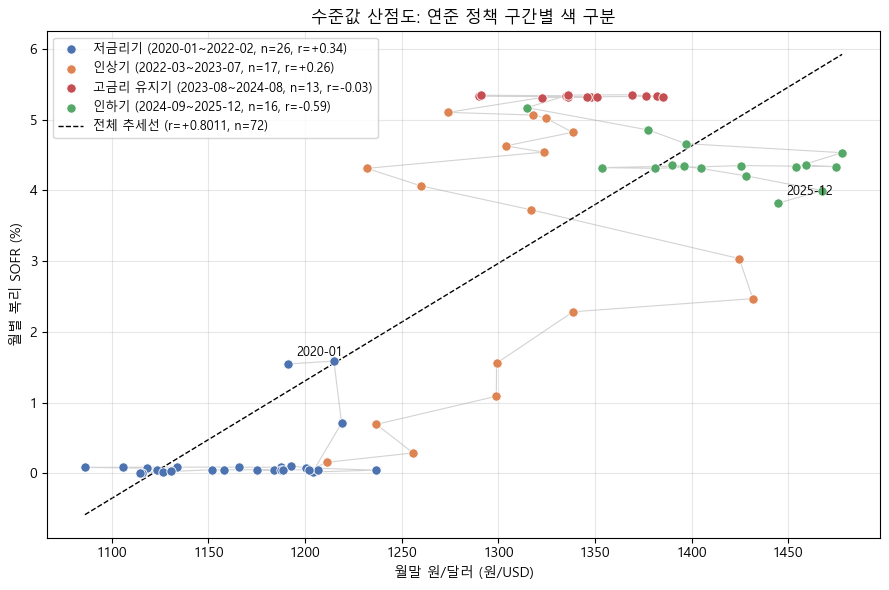

,구간,기간,개월,구간 내 상관,환율 범위(원),SOFR 범위(%)
0,저금리기,2020-01~2022-02,26,0.3397,"1,086~1,237",0.01~1.59
1,인상기,2022-03~2023-07,17,0.2559,"1,212~1,432",0.16~5.10
2,고금리 유지기,2023-08~2024-08,13,-0.0264,"1,290~1,385",5.31~5.35
3,인하기,2024-09~2025-12,16,-0.5929,"1,315~1,478",3.82~5.17


저장: figures/scatter_level_by_regime.png (마지막 ZIP 셀에서 함께 묶임)


In [ ]:
# 블록 ⑦-1. 수준값 산점도 (연준 정책 구간별 색) → figures/scatter_level_by_regime.png
import matplotlib.pyplot as plt
from analysis_core import REGIMES as CORE_REGIMES   # 구간 경계는 analysis_core 한 곳에서만 관리

print("한글 폰트:", setup_korean_font())             # 0-0 셀의 공통 함수 (Colab·윈도우·맥 모두 대응)

SC_COLORS = {"low": "#4C72B0", "hiking": "#DD8452", "hold": "#C44E52", "cutting": "#55A868"}
sx, sy = "usdkrw_end", "sofr_comp_pct"
sc_r_all = m[sx].corr(m[sy])
assert round(sc_r_all, 4) == metrics["corr_level"], "그림의 상관계수가 metrics.json과 다릅니다"

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(m[sx], m[sy], color="lightgray", lw=0.8, zorder=1)          # 시간 순서 경로
sc_rows = []
for ko, key, s, e in CORE_REGIMES:
    p = m[(m["month"] >= s) & (m["month"] <= e)]
    pr = p[sx].corr(p[sy]) if len(p) > 2 else np.nan
    ax.scatter(p[sx], p[sy], s=45, color=SC_COLORS[key], edgecolor="white", lw=0.6, zorder=2,
               label=f"{ko} ({s}~{e}, n={len(p)}, r={pr:+.2f})")
    sc_rows.append({"구간": ko, "기간": f"{s}~{e}", "개월": len(p), "구간 내 상관": round(pr, 4),
                    "환율 범위(원)": f"{p[sx].min():,.0f}~{p[sx].max():,.0f}",
                    "SOFR 범위(%)": f"{p[sy].min():.2f}~{p[sy].max():.2f}"})

b, a = np.polyfit(m[sx], m[sy], 1)                                   # 전체 추세선
xs = np.linspace(m[sx].min(), m[sx].max(), 50)
ax.plot(xs, a + b * xs, "k--", lw=1, zorder=1, label=f"전체 추세선 (r={sc_r_all:+.4f}, n={len(m)})")
for i in [0, len(m) - 1]:                                            # 시작·끝 월 표시
    ax.annotate(m["month"].iloc[i], (m[sx].iloc[i], m[sy].iloc[i]),
                xytext=(6, 6), textcoords="offset points", fontsize=9)

ax.set_xlabel("월말 원/달러 (원/USD)")
ax.set_ylabel("월별 복리 SOFR (%)")
ax.set_title("수준값 산점도: 연준 정책 구간별 색 구분")
ax.legend(fontsize=9, loc="best")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/scatter_level_by_regime.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame(sc_rows))
print("저장: figures/scatter_level_by_regime.png (마지막 ZIP 셀에서 함께 묶임)")

## 블록 ⑧. 민감도 표 (9절)
2025년 12월 실제 복리 SOFR(반올림 전 값)과 환율로 계산합니다. 원 단위 ±1 차이는 반올림 문제입니다.

In [ ]:
last = m.iloc[-1]
r, F = float(last["sofr_comp"]), float(last["usdkrw_end"])
cost = lambda rr, FF: PRINCIPAL * (rr + SPREAD) / 12 * FF
base, s_r, s_f, s_b = cost(r, F), cost(r + 0.01, F), cost(r, F * 1.1), cost(r + 0.01, F * 1.1)
sens = pd.DataFrame({"월 원화 이자": [base, s_r, s_f, s_b], "기준 대비": [0, s_r - base, s_f - base, s_b - base]},
                    index=["기준 (2025.12)", "SOFR +1%p", "원/달러 +10%", "동시 발생"]).round(0)
display(sens)
cross = (s_b - base) - (s_r - base) - (s_f - base)
compare([
    ["기준 복리 SOFR(%)", 3.82, round(r * 100, 2)],
    ["기준 원/달러", 1444.55, round(F, 2)],
    ["기준 이자", 7003762, round(base)],
    ["SOFR +1%p 이자", 8207553, round(s_r)],
    ["SOFR +1%p 증가", 1203792, round(s_r - base)],
    ["환율 +10% 이자", 7704138, round(s_f)],
    ["환율 +10% 증가", 700376, round(s_f - base)],
    ["동시 발생 이자", 9028309, round(s_b)],
    ["동시 발생 증가", 2024547, round(s_b - base)],
])
print(f"교차항(동시 - 각각의 합) = {cross:,.0f}원 → 보고서 '각각의 합보다 조금 더 커진다' {'맞음' if cross > 0 else '확인 필요'}")
aux["sensitivity_2025_12"] = {"sofr_comp": round(r, 6), "usdkrw": F,
    "base_krw": round(base), "sofr_plus_1pp_krw": round(s_r), "fx_plus_10pct_krw": round(s_f),
    "both_krw": round(s_b), "cross_term_krw": round(cross)}

,월 원화 이자,기준 대비
기준 (2025.12),7003762.0,0.0
SOFR +1%p,8207553.0,1203792.0
원/달러 +10%,7704138.0,700376.0
동시 발생,9028309.0,2024547.0


,항목,보고서,계산값,결과
0,기준 복리 SOFR(%),3.82,3.82,OK
1,기준 원/달러,1444.55,1444.55,OK
2,기준 이자,7003762.0,7003762.0,OK
3,SOFR +1%p 이자,8207553.0,8207553.0,OK
4,SOFR +1%p 증가,1203792.0,1203792.0,OK
5,환율 +10% 이자,7704138.0,7704138.0,OK
6,환율 +10% 증가,700376.0,700376.0,OK
7,동시 발생 이자,9028309.0,9028309.0,OK
8,동시 발생 증가,2024547.0,2024547.0,OK


→ 전부 OK
교차항(동시 - 각각의 합) = 120,379원 → 보고서 '각각의 합보다 조금 더 커진다' 맞음


## 블록 ⑨. 연준 정책 구간별 수준 (4절 표)
환율은 원 단위로 반올림해 비교합니다. 최저·최고 '월'만 CHK이면 같은 값이 여러 달에 있는지 확인하세요.

In [ ]:
sec4 = {}
for ko, key, s, e in REGIMES:
    p = m[(m["month"] >= s) & (m["month"] <= e)]
    sp, fx = p["sofr_comp_pct"], p["usdkrw_end"]
    sec4[key] = {"sofr_mean_pct": float(sp.mean()),
                 "sofr_first_pct": float(sp.iloc[0]), "sofr_last_pct": float(sp.iloc[-1]),
                 "sofr_min_pct": float(sp.min()), "sofr_min_month": p.loc[sp.idxmin(), "month"],
                 "sofr_max_pct": float(sp.max()), "sofr_max_month": p.loc[sp.idxmax(), "month"],
                 "fx_min": float(fx.min()), "fx_min_month": p.loc[fx.idxmin(), "month"],
                 "fx_max": float(fx.max()), "fx_max_month": p.loc[fx.idxmax(), "month"],
                 "avg_cost_30d_krw": float(p["cost_30d_krw"].mean())}
display(pd.DataFrame(sec4).T)
g = lambda k, f, d=None: (round(sec4[k][f], d) if d is not None else round(sec4[k][f])) if isinstance(sec4[k][f], float) else sec4[k][f]
w = lambda k: round(sec4[k]["avg_cost_30d_krw"] / MAN)
compare([
    ["저금리기 SOFR 평균(%)", 0.20, g("low", "sofr_mean_pct", 2)],
    ["저금리기 SOFR 최저(%)", 0.01, g("low", "sofr_min_pct", 2)],
    ["저금리기 SOFR 최저월", "2021-04", g("low", "sofr_min_month")],
    ["저금리기 환율 최저", 1086, g("low", "fx_min")], ["저금리기 환율 최저월", "2020-12", g("low", "fx_min_month")],
    ["저금리기 환율 최고", 1237, g("low", "fx_max")], ["저금리기 환율 최고월", "2020-05", g("low", "fx_max_month")],
    ["저금리기 30일 이자 평균(만원)", 214, w("low")],
    ["인상기 SOFR 시작(%)", 0.16, g("hiking", "sofr_first_pct", 2)], ["인상기 SOFR 끝(%)", 5.10, g("hiking", "sofr_last_pct", 2)],
    ["인상기 환율 최저", 1212, g("hiking", "fx_min")], ["인상기 환율 최저월", "2022-03", g("hiking", "fx_min_month")],
    ["인상기 환율 최고", 1432, g("hiking", "fx_max")], ["인상기 환율 최고월", "2022-09", g("hiking", "fx_max_month")],
    ["인상기 30일 이자 평균(만원)", 558, w("hiking")],
    ["유지기 SOFR 최저(%)", 5.31, g("hold", "sofr_min_pct", 2)], ["유지기 SOFR 최고(%)", 5.35, g("hold", "sofr_max_pct", 2)],
    ["유지기 SOFR 최고월", "2024-07", g("hold", "sofr_max_month")],
    ["유지기 환율 최저", 1290, g("hold", "fx_min")], ["유지기 환율 최저월", "2023-11", g("hold", "fx_min_month")],
    ["유지기 환율 최고", 1385, g("hold", "fx_max")], ["유지기 환율 최고월", "2024-05", g("hold", "fx_max_month")],
    ["유지기 30일 이자 평균(만원)", 821, w("hold")],
    ["인하기 SOFR 시작(%)", 5.17, g("cutting", "sofr_first_pct", 2)], ["인하기 SOFR 끝(%)", 3.82, g("cutting", "sofr_last_pct", 2)],
    ["인하기 환율 최저", 1315, g("cutting", "fx_min")], ["인하기 환율 최저월", "2024-09", g("cutting", "fx_min_month")],
    ["인하기 환율 최고", 1478, g("cutting", "fx_max")], ["인하기 환율 최고월", "2024-12", g("cutting", "fx_max_month")],
    ["인하기 30일 이자 평균(만원)", 753, w("cutting")],
    ["전체 환율 최저", 1086, round(float(m["usdkrw_end"].min()))], ["전체 환율 최저월", "2020-12", m.loc[m["usdkrw_end"].idxmin(), "month"]],
    ["전체 환율 최고", 1478, round(float(m["usdkrw_end"].max()))], ["전체 환율 최고월", "2024-12", m.loc[m["usdkrw_end"].idxmax(), "month"]],
])
aux["regime_levels"] = {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in d.items()} for k, d in sec4.items()}

,sofr_mean_pct,sofr_first_pct,sofr_last_pct,sofr_min_pct,sofr_min_month,sofr_max_pct,sofr_max_month,fx_min,fx_min_month,fx_max,fx_max_month,avg_cost_30d_krw
low,0.195624,1.545799,0.049644,0.009995,2021-04,1.586268,2020-02,1086.11,2020-12,1236.61,2020-05,2138522.885671
hiking,3.108488,0.155824,5.101734,0.155824,2022-03,5.101734,2023-07,1211.55,2022-03,1431.67,2022-09,5577926.922342
hold,5.330228,5.312061,5.346494,5.312061,2023-08,5.351401,2024-07,1289.95,2023-11,1385.43,2024-05,8208217.10635
cutting,4.390357,5.169052,3.818085,3.818085,2025-12,5.169052,2024-09,1314.94,2024-09,1477.86,2024-12,7530601.811467


,항목,보고서,계산값,결과
0,저금리기 SOFR 평균(%),0.2,0.2,OK
1,저금리기 SOFR 최저(%),0.01,0.01,OK
2,저금리기 SOFR 최저월,2021-04,2021-04,OK
3,저금리기 환율 최저,1086,1086,OK
4,저금리기 환율 최저월,2020-12,2020-12,OK
5,저금리기 환율 최고,1237,1237,OK
6,저금리기 환율 최고월,2020-05,2020-05,OK
7,저금리기 30일 이자 평균(만원),214,214,OK
8,인상기 SOFR 시작(%),0.16,0.16,OK
9,인상기 SOFR 끝(%),5.1,5.1,OK


→ 전부 OK


## 블록 ⑩. 원본 결측 · 공통일 · 기타 (3절·6절)

In [ ]:
win = lambda df: df[(df["date"] >= "2019-12-01") & (df["date"] <= "2025-12-31")]
s_raw = win(read_fred_csv(SERIES["SOFRINDEX"], "SOFRINDEX"))
f_raw = win(read_fred_csv(SERIES["DEXKOUS"], "DEXKOUS"))
def missing_on(df, day):
    row = df[df["date"] == day]
    return int(row.empty or pd.isna(row.iloc[0, 1]))
d_mar = float(m.set_index("month").loc["2020-03", "d_sofr"]) * 100 if "2020-03" in set(m["month"]) else None
compare([
    ["SOFRINDEX 결측", 69, int(s_raw.iloc[:, 1].isna().sum())],
    ["DEXKOUS 결측", 68, int(f_raw.iloc[:, 1].isna().sum())],
    ["2020-04-10 SOFR 결측 (1=예)", 1, missing_on(s_raw, "2020-04-10")],
    ["2020-04-10 환율 결측 (0=값 있음)", 0, missing_on(f_raw, "2020-04-10")],
    ["2020-10-12 둘 다 결측 (1=예)", 1, int(missing_on(s_raw, "2020-10-12") and missing_on(f_raw, "2020-10-12"))],
    ["공통 유효일 전체", 1514, len(win(daily))],
    ["공통 유효일 2020~2025", 1493, n_daily],
    ["2020-03 SOFR 변화(%p)", -0.88, round(d_mar, 2) if d_mar is not None else None],
    ["분해 최대 오차 < 1e-8원 (1=예)", 1, int(metrics["max_decomp_residual"] < 1e-8)],
])
print(f"분해 최대 오차: {metrics['max_decomp_residual']:.1e}원 (보고서 0.000000002원)")
aux["data_checks"] = {"raw_missing_sofrindex": int(s_raw.iloc[:, 1].isna().sum()),
    "raw_missing_dexkous": int(f_raw.iloc[:, 1].isna().sum()), "common_days_all": len(win(daily)),
    "common_days_2020_2025": n_daily, "d_sofr_2020_03_pp": round(d_mar, 4) if d_mar is not None else None}

,항목,보고서,계산값,결과
0,SOFRINDEX 결측,69.0,69.0,OK
1,DEXKOUS 결측,68.0,68.0,OK
2,2020-04-10 SOFR 결측 (1=예),1.0,1.0,OK
3,2020-04-10 환율 결측 (0=값 있음),0.0,0.0,OK
4,2020-10-12 둘 다 결측 (1=예),1.0,1.0,OK
5,공통 유효일 전체,1514.0,1514.0,OK
6,공통 유효일 2020~2025,1493.0,1493.0,OK
7,2020-03 SOFR 변화(%p),-0.88,-0.88,OK
8,분해 최대 오차 < 1e-8원 (1=예),1.0,1.0,OK


→ 전부 OK
분해 최대 오차: 2.3e-09원 (보고서 0.000000002원)


## 함수 결과 대조
`compute_auxiliary()` 결과가 위 셀 계산값, 그리고 v1.1(윤호 님이 받은 값)과 완전히 같은지 확인합니다.

In [ ]:
# 함수로 다시 계산 → 셀 계산값(aux)·v1.1 값과 완전히 같은지 확인
import importlib, analysis_core
importlib.reload(analysis_core)
from analysis_core import compute_auxiliary

aux_func = compute_auxiliary(m, daily, n_daily, SERIES, PRINCIPAL, SPREAD, DOWNLOAD_DATE, DOWNLOAD_METHOD)

def same(a, b):
    return json.dumps(a, sort_keys=True, default=str) == json.dumps(b, sort_keys=True, default=str)

def drop_mtime(d):   # 업로드·압축 해제 시각은 실행마다 달라서 비교에서 제외
    d = json.loads(json.dumps(d, default=str))
    for f in d.get("files", {}).values():
        f.pop("file_modified_in_runtime", None)
    return d

rows = []
for k in aux_func:
    cell = aux.get(k)
    prev = metrics.get("auxiliary", {}).get(k)       # v1.1에서 불러온 값 (윤호님이 받은 값)
    if k == "data_provenance":
        cell, prev, fn = drop_mtime(cell or {}), (drop_mtime(prev) if prev else None), drop_mtime(aux_func[k])
    else:
        fn = aux_func[k]
    rows.append({"지표": k,
                 "셀 계산 = 함수": "OK" if cell is not None and same(cell, fn) else ("없음" if cell is None else "CHK"),
                 "v1.1 = 함수": "OK" if prev is not None and same(prev, fn) else ("v1.1에 없음" if prev is None else "CHK")})
t = pd.DataFrame(rows)
display(t)
assert not (t[["셀 계산 = 함수", "v1.1 = 함수"]] == "CHK").any().any(), "함수 결과가 기존 값과 다릅니다"

aux = aux_func                                        # 저장은 함수 결과로
metrics["auxiliary_function"] = "analysis_core.compute_auxiliary"
print("→ 함수 결과가 기존 값과 동일. 저장 셀에서 이 값으로 metrics.json을 씁니다.")

,지표,셀 계산 = 함수,v1.1 = 함수
0,subperiod_corr,OK,v1.1에 없음
1,regime_contrib,OK,v1.1에 없음
2,top3_contrib,OK,v1.1에 없음
3,data_provenance,OK,v1.1에 없음
4,concentration,OK,v1.1에 없음
5,yearly_dominance,OK,v1.1에 없음
6,scatter_clusters,OK,v1.1에 없음
7,sensitivity_2025_12,OK,v1.1에 없음
8,regime_levels,OK,v1.1에 없음
9,data_checks,OK,v1.1에 없음


→ 함수 결과가 기존 값과 동일. 저장 셀에서 이 값으로 metrics.json을 씁니다.


## 저장. metrics.json v1.2 (핵심 수치는 그대로, auxiliary에 추가)

In [ ]:
AUX_VERSION = "v1.2"
old_core = {k: metrics[k] for k in ["corr_level", "corr_change", "fx_dominant_months",
            "sum_abs_contrib_rate_krw", "sum_abs_contrib_fx_krw"]}
metrics["auxiliary"] = aux
metrics["version"] = AUX_VERSION
log = [c for c in metrics.get("changelog", []) if c["version"] != AUX_VERSION]   # 재실행해도 중복 기록 안 됨
metrics["changelog"] = log + [
    {"version": AUX_VERSION, "date": datetime.now().strftime("%Y-%m-%d"),
     "change": "auxiliary verification of remaining report figures added (concentration, yearly dominance, scatter clusters, sensitivity, regime levels, data checks); auxiliary functions added to analysis_core.py (compute_auxiliary); core values unchanged"}]
assert all(metrics[k] == v_ for k, v_ in old_core.items()), "핵심 수치가 바뀌었습니다"
Path("processed/metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("processed/metrics.json 저장 완료 →", AUX_VERSION)

processed/metrics.json 저장 완료 → v1.2


## 결과 내려받기 (ZIP)

In [ ]:
VERSION = metrics["version"]
shutil.copy("analysis_core.py", "processed/analysis_core.py")
Path("requirements.txt").write_text("pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\n")
out = f"data_part_{VERSION}"
Path(out).mkdir(exist_ok=True)
for p in ["raw", "processed", "figures"]:
    shutil.copytree(p, f"{out}/{p}", dirs_exist_ok=True)
shutil.copy("requirements.txt", out)
shutil.make_archive(out, "zip", out)
print(f"{out}.zip 생성")
offer_download(f"{out}.zip")

data_part_v1.2.zip 생성
저장 위치: C:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source\_run\data_part_v1.2.zip


## (선택) 공유 폴더로 그림 복사
기본은 꺼져 있습니다. 팀원이 공유 폴더에 올릴 때만 `COPY_TO_TEAM = True`로 바꿔 이 셀만 실행합니다.

In [ ]:
# 공유 폴더로 그림 복사 (팀원 전용 · 기본은 꺼짐)
# 채점자 등 공유 폴더가 없는 환경에서는 False 그대로 두면 아무 일도 하지 않음
COPY_TO_TEAM = False                  # 팀원이 공유 폴더에 올릴 때만 True
DEST_DIR = "_작업중_제출제외"          # 보고서 사용 확정 후에는 "output/figures"
SRC = Path("figures/scatter_level_by_regime.png")

def file_hash(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

if not COPY_TO_TEAM:
    print("COPY_TO_TEAM = False → 공유 폴더 복사 생략 (그림은 figures/와 ZIP에 있음)")
else:
    team = PROJECT or find_project_root()   # Colab: Drive 바로가기 / 로컬: 동기화 폴더·PROJECT_ROOT
    assert team is not None, "공유 폴더를 찾지 못했습니다 (Colab: 바로가기 추가 / 로컬: PROJECT_ROOT 지정)"
    assert SRC.exists(), "블록 ⑦-1을 먼저 실행하세요"
    dest = team / DEST_DIR / SRC.name
    dest.parent.mkdir(parents=True, exist_ok=True)
    # 폴더 규칙: 덮어쓰지 않음. 같은 그림이면 건너뛰고, 다르면 _v2, _v3 … 로 저장
    if dest.exists():
        same = [q for q in dest.parent.glob(f"{SRC.stem}*{SRC.suffix}") if file_hash(q) == file_hash(SRC)]
        if same:
            print("같은 그림이 이미 있어 건너뜀:", same[0])
            dest = None
        else:
            k = 2
            while dest.with_name(f"{SRC.stem}_v{k}{SRC.suffix}").exists():
                k += 1
            dest = dest.with_name(f"{SRC.stem}_v{k}{SRC.suffix}")
    if dest:
        shutil.copy2(SRC, dest)
        print("복사 완료:", dest)

COPY_TO_TEAM = False → 공유 폴더 복사 생략 (그림은 figures/와 ZIP에 있음)
